# code_061 · Leakage cost and feature availability

**Book:** section 12.5. A self-contained feature-engineering laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_12_GUIDE.md), [run evidence](../CHAPTER_12_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_061).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Construction audits are distinct from predictive assessment; fitted examples declare training/development/final roles locally. All numerical data are generated. These comparisons expose representation assumptions, fitting boundaries and operational constraints without field-validity, causal or universal feature-selection claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1261;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1261


<a id="packages"></a>
## Compare operational feature packages, not isolated scores

Generate 700 independent members with current base measurement x, latent condition z and later displacement y=.8*x+1.2*z+Normal(0,.25) mm. Vibration measures z with noise .7, costs 5 teaching currency units and arrives .1 day after request. A preplanned prior inspection measures z with noise 1, costs 20 and is already available at cutoff (it required earlier scheduling). A new precise inspection has noise .1, costs 50 and arrives two days later. An outcome-derived proxy y+noise .01 arrives after day 7, when the target is reported. This static-state simulator omits condition dynamics and actual economic utility.

The original decision deadline is .5 day and evidence budget 25. Four lawful packages use base, base+vibration, base+prior, or base+both. Two diagnostic invalid packages append the late new inspection or outcome proxy. Every fixed predictor is training StandardScaler+Ridge alpha=1; train/development/final counts are 400/150/150. Choose the lowest development MSE among packages meeting the predeclared deadline/budget. A later decision would be another task and needs its own outcome definition; this lab does not convert a missed deadline into a valid forecast.


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
x=rng.normal(size=700);z=rng.normal(size=700);y=.8*x+1.2*z+rng.normal(0,.25,700);features={'base':x,'vibration':z+rng.normal(0,.7,700),'prior':z+rng.normal(0,1,700),'late_new':z+rng.normal(0,.1,700),'outcome_proxy':y+rng.normal(0,.01,700)}
packages={'base':(['base'],0.,0.),'vibration':(['base','vibration'],5.,.1),'prior':(['base','prior'],20.,0.),'both':(['base','vibration','prior'],25.,.1),'late_new_INVALID':(['base','late_new'],50.,2.),'outcome_proxy_INVALID':(['base','outcome_proxy'],0.,7.1)}
tr=np.arange(400);dv=np.arange(400,550);te=np.arange(550,700);assert not set(tr)&set(dv) and not set(tr)&set(te) and not set(dv)&set(te)
metrics={};fitted={}
for name,(columns,cost,latency) in packages.items():
 A=np.column_stack([features[k] for k in columns]);fit=make_pipeline(StandardScaler(),Ridge(alpha=1)).fit(A[tr],y[tr]);eligible=cost<=25 and latency<=.5 and 'INVALID' not in name
 metrics[name]={'columns':columns,'cost':cost,'latency_days':latency,'eligible':eligible,'development_MSE_mm2':float(mean_squared_error(y[dv],fit.predict(A[dv]))),'final_or_invalid_apparent_MSE_mm2':float(mean_squared_error(y[te],fit.predict(A[te])))};fitted[name]=fit
eligible=[k for k in packages if metrics[k]['eligible']];selected=min(eligible,key=lambda k:metrics[k]['development_MSE_mm2']);assert metrics[selected]['eligible'] and selected in ['base','vibration','prior','both']
RESULTS['packages']=metrics;RESULTS['selected_on_development']=selected;RESULTS['selected_final_MSE_mm2']=metrics[selected]['final_or_invalid_apparent_MSE_mm2'];RESULTS['budget']=25;RESULTS['deadline_days']=.5


<a id="audit"></a>
## Reject unavailable columns and schema reorderings

A near-perfect outcome proxy is an audit finding, not a deployable feature. The late inspection's apparent score describes information the original decision cannot have. Store names and order with the selected package; a reordered request must be detected rather than silently fed to the fitted scaler. The same-cost budget does not imply equal staffing, reliability or actual utility; currency and latency are declared teaching assumptions. Report eligible errors and invalid apparent scores with different status.


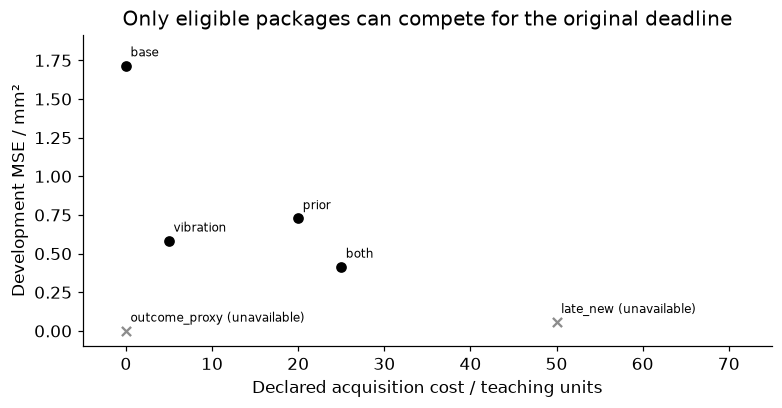

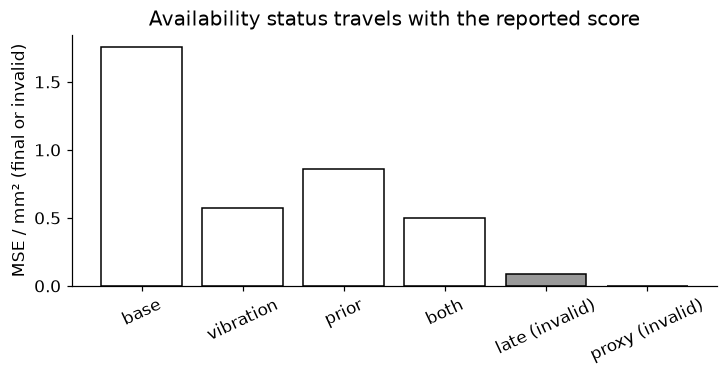

In [3]:
expected=packages[selected][0]
def predict_request(columns,values):
 if columns!=expected:raise ValueError('Column contract mismatch')
 A=np.asarray(values,dtype=float)
 if A.shape[1]!=len(expected) or not np.isfinite(A).all():raise ValueError('Invalid input shape/value')
 return fitted[selected].predict(A)
A=np.column_stack([features[k][te] for k in expected]);np.testing.assert_allclose(predict_request(expected,A),fitted[selected].predict(A))
if len(expected)>1:
 try:predict_request(expected[::-1],A[:,::-1])
 except ValueError:RESULTS['reordered_schema_rejected']=True
 else:raise AssertionError('Expected reordered schema rejection')
else:RESULTS['reordered_schema_rejected']='not applicable to single-column selected package'
assert all(metrics[k]['latency_days']<=.5 for k in eligible)
fig,ax=plt.subplots(figsize=(7,3.6));names=list(packages)
for name in names:
 r=metrics[name];ax.scatter(r['cost'],r['development_MSE_mm2'],marker='o' if r['eligible'] else 'x',color='black' if r['eligible'] else '.55');ax.annotate(name.replace('_INVALID',' (unavailable)'),(r['cost'],r['development_MSE_mm2']),xytext=(3,6),textcoords='offset points',fontsize=8)
ax.set(xlim=(-5,75),ylim=(-.1,max(r['development_MSE_mm2'] for r in metrics.values())+.2),xlabel='Declared acquisition cost / teaching units',ylabel='Development MSE / mm²',title='Only eligible packages can compete for the original deadline');plt.show()
fig,ax=plt.subplots(figsize=(6.5,3.3));values=[metrics[k]['final_or_invalid_apparent_MSE_mm2'] for k in names];ax.bar(np.arange(len(names)),values,color=['white' if metrics[k]['eligible'] else '.6' for k in names],edgecolor='black');ax.set(xticks=np.arange(len(names)),xticklabels=['base','vibration','prior','both','late (invalid)','proxy (invalid)'],ylabel='MSE / mm² (final or invalid)',title='Availability status travels with the reported score');ax.tick_params(axis='x',labelrotation=25);plt.show()


In [4]:
summary={'example_id':'code_061','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['feature acquisition cost and latency', 'future target proxies and apparent error', 'development-only package choice', 'train-serving column contract'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["feature acquisition cost and latency", "future target proxies and apparent error", "development-only package choice", "train-serving column contract"], "elapsed_seconds": 0.235, "example_id": "code_061", "hardware": "Darwin arm64 CPU", "results": {"budget": 25, "deadline_days": 0.5, "packages": {"base": {"columns": ["base"], "cost": 0.0, "development_MSE_mm2": 1.715930323972142, "eligible": true, "final_or_invalid_apparent_MSE_mm2": 1.7591248352920565, "latency_days": 0.0}, "both": {"columns": ["base", "vibration", "prior"], "cost": 25.0, "development_MSE_mm2": 0.4139675596517586, "eligible": true, "final_or_invalid_apparent_MSE_mm2": 0.4952343898236713, "latency_days": 0.1}, "late_new_INVALID": {"columns": ["base", "late_new"], "cost": 50.0, "development_MSE_mm2": 0.05615321367081568, "eligible": false, "final_or_invalid_apparent_MSE_mm2": 0.08883550193584965, "latency_days": 2.0}, "outcome_proxy_INVALID": {"columns": ["base", "outcom